Start Feature Engineering

In [5]:
# ============================================================
# PHASE 4: FEATURE ENGINEERING
# SmartPlate Food Waste Reduction Project
# ============================================================

print("=" * 70)
print("PHASE 4: FEATURE ENGINEERING")
print("=" * 70)

PHASE 4: FEATURE ENGINEERING


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv(r"C:\Users\Aaditya babaso patil\Desktop\SmartPlate_Data_Mining_Project\data\smartplate_cafeteria_dataset.csv")

print("Original Dataset Shape:", df.shape)

print("\nCurrent Columns:")
print(df.columns.tolist())

Original Dataset Shape: (21900, 19)

Current Columns:
['Date', 'Day_of_Week', 'Food_Item', 'Food_Category', 'Meal_Type', 'Quantity_Prepared', 'Quantity_Sold', 'Quantity_Wasted', 'Actual_Demand', 'Number_of_Students', 'Weather', 'Temperature', 'Special_Event_Flag', 'Holiday_Flag', 'Food_Cost_Per_Unit', 'Selling_Price_Per_Unit', 'Estimated_Cost_of_Waste', 'Unmet_Demand', 'Stockout_Flag']


Check required columns

In [8]:
# Required columns for feature engineering

required_columns = [
    'Quantity_Prepared',
    'Quantity_Sold',
    'Quantity_Wasted',
    'Selling_Price_Per_Unit',
    'Food_Cost_Per_Unit',
    'Estimated_Cost_of_Waste',
    'Food_Category',
    'Meal_Type',
    'Stockout_Flag',
    'Temperature'
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if len(missing_columns) == 0:
    print("✅ All required columns are available.")
else:
    print("❌ Missing columns:")
    print(missing_columns)

✅ All required columns are available.


 Basic validation

In [9]:
# ============================================================
# BASIC DATA VALIDATION
# ============================================================

numeric_columns = [
    'Quantity_Prepared',
    'Quantity_Sold',
    'Quantity_Wasted',
    'Selling_Price_Per_Unit',
    'Food_Cost_Per_Unit',
    'Estimated_Cost_of_Waste',
    'Stockout_Flag',
    'Temperature'
]

print("Negative values check:")

for col in numeric_columns:
    if col in df.columns:
        negative_count = (df[col] < 0).sum()
        print(f"{col}: {negative_count}")

Negative values check:
Quantity_Prepared: 0
Quantity_Sold: 0
Quantity_Wasted: 0
Selling_Price_Per_Unit: 0
Food_Cost_Per_Unit: 0
Estimated_Cost_of_Waste: 0
Stockout_Flag: 0
Temperature: 0


Waste Percentage

In [10]:
# ============================================================
# FEATURE 1: WASTE PERCENTAGE
# ============================================================

df['Waste_Percentage'] = np.where(
    df['Quantity_Prepared'] > 0,
    (df['Quantity_Wasted'] / df['Quantity_Prepared']) * 100,
    0
)

print("Waste Percentage created successfully.")

print(
    df[
        [
            'Quantity_Prepared',
            'Quantity_Wasted',
            'Waste_Percentage'
        ]
    ].head()
)

Waste Percentage created successfully.
   Quantity_Prepared  Quantity_Wasted  Waste_Percentage
0              41.07             1.98          4.821037
1              41.47             1.37          3.303593
2              40.15             2.94          7.322540
3              77.84            20.31         26.091984
4              40.98             1.10          2.684236


Food Utilization Rate

In [11]:
# ============================================================
# FEATURE 2: FOOD UTILIZATION RATE
# ============================================================

df['Food_Utilization_Rate'] = np.where(
    df['Quantity_Prepared'] > 0,
    (df['Quantity_Sold'] / df['Quantity_Prepared']) * 100,
    0
)

print(
    df[
        [
            'Quantity_Prepared',
            'Quantity_Sold',
            'Food_Utilization_Rate'
        ]
    ].head()
)

   Quantity_Prepared  Quantity_Sold  Food_Utilization_Rate
0              41.07          39.09              95.178963
1              41.47          40.10              96.696407
2              40.15          37.21              92.677460
3              77.84          57.53              73.908016
4              40.98          39.88              97.315764


Preparation Buffer

In [12]:
# ============================================================
# FEATURE 3: PREPARATION BUFFER
# ============================================================

df['Preparation_Buffer'] = (
    df['Quantity_Prepared'] -
    df['Quantity_Sold']
)

print(
    df[
        [
            'Quantity_Prepared',
            'Quantity_Sold',
            'Preparation_Buffer'
        ]
    ].head()
)

   Quantity_Prepared  Quantity_Sold  Preparation_Buffer
0              41.07          39.09                1.98
1              41.47          40.10                1.37
2              40.15          37.21                2.94
3              77.84          57.53               20.31
4              40.98          39.88                1.10


In [13]:
# ============================================================
# FEATURE 4: WASTE COST PER UNIT
# ============================================================

df['Waste_Cost_Per_Unit'] = np.where(
    df['Quantity_Wasted'] > 0,
    df['Estimated_Cost_of_Waste'] /
    df['Quantity_Wasted'],
    0
)

print(
    df[
        [
            'Quantity_Wasted',
            'Estimated_Cost_of_Waste',
            'Waste_Cost_Per_Unit'
        ]
    ].head()
)

   Quantity_Wasted  Estimated_Cost_of_Waste  Waste_Cost_Per_Unit
0             1.98                     1.58             0.797980
1             1.37                     1.09             0.795620
2             2.94                     2.94             1.000000
3            20.31                    10.15             0.499754
4             1.10                     3.31             3.009091


In [14]:
# ============================================================
# FEATURE 5: PROFIT PER SOLD UNIT
# ============================================================

# Create Total Revenue
df['Total_Revenue'] = (
    df['Quantity_Sold'] *
    df['Selling_Price_Per_Unit']
)

# Create Total Cost
df['Total_Cost'] = (
    df['Quantity_Sold'] *
    df['Food_Cost_Per_Unit']
)

# Create Net Profit
df['Net_Profit'] = (
    df['Total_Revenue'] -
    df['Total_Cost']
)

# Create Profit Per Sold Unit
df['Profit_Per_Sold_Unit'] = np.where(
    df['Quantity_Sold'] > 0,
    df['Net_Profit'] / df['Quantity_Sold'],
    0
)

print("✅ Net_Profit created")
print("✅ Profit_Per_Sold_Unit created")

display(
    df[
        [
            'Quantity_Sold',
            'Selling_Price_Per_Unit',
            'Food_Cost_Per_Unit',
            'Total_Revenue',
            'Total_Cost',
            'Net_Profit',
            'Profit_Per_Sold_Unit'
        ]
    ].head()
)

✅ Net_Profit created
✅ Profit_Per_Sold_Unit created


,Quantity_Sold,Selling_Price_Per_Unit,Food_Cost_Per_Unit,Total_Revenue,Total_Cost,Net_Profit,Profit_Per_Sold_Unit
0,39.09,1.5,0.8,58.635,31.272,27.363,0.7
1,40.10,1.5,0.8,60.150,32.080,28.070,0.7
2,37.21,2.0,1.0,74.420,37.210,37.210,1.0
3,57.53,1.0,0.5,57.530,28.765,28.765,0.5
4,39.88,5.0,3.0,199.400,119.640,79.760,2.0


In [15]:
# ============================================================
# FEATURE 6: FOOD COST PERCENTAGE
# ============================================================

df['Food_Cost_Percentage'] = np.where(
    df['Selling_Price_Per_Unit'] > 0,
    (
        df['Food_Cost_Per_Unit'] /
        df['Selling_Price_Per_Unit']
    ) * 100,
    0
)

print(
    df[
        [
            'Selling_Price_Per_Unit',
            'Food_Cost_Per_Unit',
            'Food_Cost_Percentage'
        ]
    ].head()
)

   Selling_Price_Per_Unit  Food_Cost_Per_Unit  Food_Cost_Percentage
0                     1.5                 0.8             53.333333
1                     1.5                 0.8             53.333333
2                     2.0                 1.0             50.000000
3                     1.0                 0.5             50.000000
4                     5.0                 3.0             60.000000


In [16]:
# ============================================================
# FEATURE 7: HIGH WASTE FLAG
# ============================================================

waste_threshold = df['Waste_Percentage'].median()

print("Median Waste Percentage:",
      round(waste_threshold, 2))

df['High_Waste_Flag'] = (
    df['Waste_Percentage'] > waste_threshold
).astype(int)

print("\nHigh Waste Flag:")
print(df['High_Waste_Flag'].value_counts())

print(
    df[
        [
            'Waste_Percentage',
            'High_Waste_Flag'
        ]
    ].head()
)

Median Waste Percentage: 6.42

High Waste Flag:
High_Waste_Flag
0    10950
1    10950
Name: count, dtype: int64
   Waste_Percentage  High_Waste_Flag
0          4.821037                0
1          3.303593                0
2          7.322540                1
3         26.091984                1
4          2.684236                0


In [17]:
# ============================================================
# FEATURE 8: STOCKOUT STATUS
# ============================================================

df['Stockout_Status'] = np.where(
    df['Stockout_Flag'] == 1,
    'Stockout',
    'No Stockout'
)

print(df['Stockout_Status'].value_counts())

Stockout_Status
No Stockout    20410
Stockout        1490
Name: count, dtype: int64


In [18]:
# ============================================================
# FEATURE 9: TEMPERATURE CATEGORY
# ============================================================

df['Temperature_Category'] = pd.cut(
    df['Temperature'],
    bins=[-np.inf, 20, 25, 30, np.inf],
    labels=[
        'Cool',
        'Moderate',
        'Warm',
        'Hot'
    ]
)

print(df['Temperature_Category'].value_counts())

Temperature_Category
Warm        9120
Hot         5280
Moderate    4890
Cool        2610
Name: count, dtype: int64


In [19]:
# ============================================================
# FEATURE 10: FOOD POPULARITY GROUP
# ============================================================

food_sales_avg = (
    df.groupby('Food_Item')['Quantity_Sold']
      .transform('mean')
)

df['Food_Popularity_Group'] = pd.qcut(
    food_sales_avg.rank(method='first'),
    q=3,
    labels=[
        'Low',
        'Medium',
        'High'
    ]
)

print(
    df[
        [
            'Food_Item',
            'Quantity_Sold',
            'Food_Popularity_Group'
        ]
    ].head(10)
)

      Food_Item  Quantity_Sold Food_Popularity_Group
0    Buttermilk          39.09                   Low
1        Coffee          40.10                Medium
2   Lemon Juice          37.21                   Low
3           Tea          57.53                Medium
4  Aloo Paratha          39.88                   Low
5   Idli Sambar         106.36                  High
6   Masala Dosa          63.87                Medium
7     Misal Pav          40.29                   Low
8          Poha          56.50                Medium
9          Upma          41.98                   Low


In [20]:
# ============================================================
# FEATURE 11: WASTE SEVERITY
# ============================================================

df['Waste_Severity'] = pd.cut(
    df['Waste_Percentage'],
    bins=[
        -np.inf,
        10,
        25,
        50,
        np.inf
    ],
    labels=[
        'Low',
        'Moderate',
        'High',
        'Critical'
    ]
)

print(df['Waste_Severity'].value_counts())

Waste_Severity
Low         19482
Moderate     2180
High          238
Critical        0
Name: count, dtype: int64


In [21]:
# ============================================================
# FEATURE 12: REVENUE PER PREPARED UNIT
# ============================================================

df['Revenue_Per_Prepared_Unit'] = np.where(
    df['Quantity_Prepared'] > 0,
    df['Total_Revenue'] /
    df['Quantity_Prepared'],
    0
)

print(
    df[
        [
            'Total_Revenue',
            'Quantity_Prepared',
            'Revenue_Per_Prepared_Unit'
        ]
    ].head()
)

   Total_Revenue  Quantity_Prepared  Revenue_Per_Prepared_Unit
0         58.635              41.07                   1.427684
1         60.150              41.47                   1.450446
2         74.420              40.15                   1.853549
3         57.530              77.84                   0.739080
4        199.400              40.98                   4.865788


In [22]:
# ============================================================
# FEATURE 13: WASTE COST RATIO
# ============================================================

df['Waste_Cost_Ratio'] = np.where(
    df['Total_Cost'] > 0,
    (
        df['Estimated_Cost_of_Waste'] /
        df['Total_Cost']
    ) * 100,
    0
)

print(
    df[
        [
            'Estimated_Cost_of_Waste',
            'Total_Cost',
            'Waste_Cost_Ratio'
        ]
    ].head()
)

   Estimated_Cost_of_Waste  Total_Cost  Waste_Cost_Ratio
0                     1.58      31.272          5.052443
1                     1.09      32.080          3.397756
2                     2.94      37.210          7.901102
3                    10.15      28.765         35.285938
4                     3.31     119.640          2.766633


In [23]:
# ============================================================
# FEATURE 14: CATEGORY AVERAGE WASTE
# ============================================================

category_waste_avg = (
    df.groupby('Food_Category')['Waste_Percentage']
      .transform('mean')
)

df['Category_Avg_Waste_Percentage'] = category_waste_avg

print(
    df[
        [
            'Food_Category',
            'Waste_Percentage',
            'Category_Avg_Waste_Percentage'
        ]
    ].head()
)

  Food_Category  Waste_Percentage  Category_Avg_Waste_Percentage
0      Beverage          4.821037                       6.680912
1      Beverage          3.303593                       6.680912
2      Beverage          7.322540                       6.680912
3      Beverage         26.091984                       6.680912
4   Main Course          2.684236                       6.620998


In [24]:
# ============================================================
# FEATURE 15: MEAL AVERAGE WASTE
# ============================================================

meal_waste_avg = (
    df.groupby('Meal_Type')['Waste_Percentage']
      .transform('mean')
)

df['Meal_Avg_Waste_Percentage'] = meal_waste_avg

print(
    df[
        [
            'Meal_Type',
            'Waste_Percentage',
            'Meal_Avg_Waste_Percentage'
        ]
    ].head()
)

   Meal_Type  Waste_Percentage  Meal_Avg_Waste_Percentage
0  Beverages          4.821037                   6.680912
1  Beverages          3.303593                   6.680912
2  Beverages          7.322540                   6.680912
3  Beverages         26.091984                   6.680912
4  Breakfast          2.684236                   6.666646


In [25]:
# ============================================================
# OPTIONAL DATE FEATURES
# ============================================================

if 'Date' in df.columns:

    df['Date'] = pd.to_datetime(
        df['Date'],
        errors='coerce'
    )

    df['Year'] = df['Date'].dt.year
    df['Month'] = df['Date'].dt.month
    df['Month_Name'] = df['Date'].dt.month_name()

    df['Weekday_Number'] = df['Date'].dt.weekday
    df['Weekday_Name'] = df['Date'].dt.day_name()

    df['Is_Weekend'] = (
        df['Weekday_Number'] >= 5
    ).astype(int)

    print("✅ Date features created.")

else:
    print("ℹ️ Date column is not available.")
    print("Date-based features were skipped.")

✅ Date features created.


In [26]:
# ============================================================
# OPTIONAL DEMAND FEATURES
# ============================================================

if 'Actual_Demand' in df.columns:

    if 'Number_of_Students' in df.columns:

        df['Demand_Per_Student'] = np.where(
            df['Number_of_Students'] > 0,
            df['Actual_Demand'] /
            df['Number_of_Students'],
            0
        )

        print("✅ Demand_Per_Student created.")

    else:
        print(
            "ℹ️ Number_of_Students column "
            "is not available."
        )

else:
    print(
        "ℹ️ Actual_Demand column is not available."
    )

✅ Demand_Per_Student created.


In [27]:
# ============================================================
# OPTIONAL: DEMAND-BASED PREPARATION BUFFER
# ============================================================

if 'Actual_Demand' in df.columns:

    df['Demand_Based_Preparation_Buffer'] = (
        df['Quantity_Prepared'] -
        df['Actual_Demand']
    )

    print(
        df[
            [
                'Quantity_Prepared',
                'Actual_Demand',
                'Demand_Based_Preparation_Buffer'
            ]
        ].head()
    )

   Quantity_Prepared  Actual_Demand  Demand_Based_Preparation_Buffer
0              41.07          39.09                             1.98
1              41.47          40.10                             1.37
2              40.15          37.21                             2.94
3              77.84          57.53                            20.31
4              40.98          39.88                             1.10


In [28]:
# ============================================================
# FEATURE ENGINEERING SUMMARY
# ============================================================

new_features = [
    'Waste_Percentage',
    'Food_Utilization_Rate',
    'Preparation_Buffer',
    'Waste_Cost_Per_Unit',
    'Profit_Per_Sold_Unit',
    'Food_Cost_Percentage',
    'High_Waste_Flag',
    'Stockout_Status',
    'Temperature_Category',
    'Food_Popularity_Group',
    'Waste_Severity',
    'Revenue_Per_Prepared_Unit',
    'Waste_Cost_Ratio',
    'Category_Avg_Waste_Percentage',
    'Meal_Avg_Waste_Percentage'
]

# Add optional features if they exist
optional_features = [
    'Year',
    'Month',
    'Month_Name',
    'Weekday_Number',
    'Weekday_Name',
    'Is_Weekend',
    'Demand_Per_Student',
    'Demand_Based_Preparation_Buffer'
]

all_features = new_features + optional_features

available_features = [
    feature for feature in all_features
    if feature in df.columns
]

print("=" * 70)
print("FEATURE ENGINEERING SUMMARY")
print("=" * 70)

print("\nNew Features Created:")

for i, feature in enumerate(
    available_features,
    start=1
):
    print(f"{i}. {feature}")

print(
    "\nNumber of new features:",
    len(available_features)
)

print(
    "\nFinal Dataset Shape:",
    df.shape
)

FEATURE ENGINEERING SUMMARY

New Features Created:
1. Waste_Percentage
2. Food_Utilization_Rate
3. Preparation_Buffer
4. Waste_Cost_Per_Unit
5. Profit_Per_Sold_Unit
6. Food_Cost_Percentage
7. High_Waste_Flag
8. Stockout_Status
9. Temperature_Category
10. Food_Popularity_Group
11. Waste_Severity
12. Revenue_Per_Prepared_Unit
13. Waste_Cost_Ratio
14. Category_Avg_Waste_Percentage
15. Meal_Avg_Waste_Percentage
16. Year
17. Month
18. Month_Name
19. Weekday_Number
20. Weekday_Name
21. Is_Weekend
22. Demand_Per_Student
23. Demand_Based_Preparation_Buffer

Number of new features: 23

Final Dataset Shape: (21900, 45)


In [29]:
# ============================================================
# VIEW FEATURE ENGINEERED DATASET
# ============================================================

display(df.head(10))

,Date,Day_of_Week,Food_Item,Food_Category,Meal_Type,Quantity_Prepared,Quantity_Sold,Quantity_Wasted,Actual_Demand,Number_of_Students,...,Category_Avg_Waste_Percentage,Meal_Avg_Waste_Percentage,Year,Month,Month_Name,Weekday_Number,Weekday_Name,Is_Weekend,Demand_Per_Student,Demand_Based_Preparation_Buffer
0,2025-01-01,Wednesday,Buttermilk,Beverage,Beverages,41.07,39.09,1.98,39.09,171.55,...,6.680912,6.680912,2025,1,January,2,Wednesday,0,0.227864,1.98
1,2025-01-01,Wednesday,Coffee,Beverage,Beverages,41.47,40.10,1.37,40.10,171.55,...,6.680912,6.680912,2025,1,January,2,Wednesday,0,0.233751,1.37
2,2025-01-01,Wednesday,Lemon Juice,Beverage,Beverages,40.15,37.21,2.94,37.21,171.55,...,6.680912,6.680912,2025,1,January,2,Wednesday,0,0.216905,2.94
3,2025-01-01,Wednesday,Tea,Beverage,Beverages,77.84,57.53,20.31,57.53,171.55,...,6.680912,6.680912,2025,1,January,2,Wednesday,0,0.335354,20.31
4,2025-01-01,Wednesday,Aloo Paratha,Main Course,Breakfast,40.98,39.88,1.10,39.88,171.55,...,6.620998,6.666646,2025,1,January,2,Wednesday,0,0.232469,1.10
5,2025-01-01,Wednesday,Idli Sambar,Main Course,Breakfast,106.36,106.36,0.00,116.79,171.55,...,6.620998,6.666646,2025,1,January,2,Wednesday,0,0.680793,-10.43
6,2025-01-01,Wednesday,Masala Dosa,Main Course,Breakfast,67.33,63.87,3.46,63.87,171.55,...,6.620998,6.666646,2025,1,January,2,Wednesday,0,0.372311,3.46
7,2025-01-01,Wednesday,Misal Pav,Main Course,Breakfast,41.27,40.29,0.98,40.29,171.55,...,6.620998,6.666646,2025,1,January,2,Wednesday,0,0.234859,0.98
8,2025-01-01,Wednesday,Poha,Main Course,Breakfast,61.00,56.50,4.50,56.50,171.55,...,6.620998,6.666646,2025,1,January,2,Wednesday,0,0.329350,4.50
9,2025-01-01,Wednesday,Upma,Main Course,Breakfast,42.51,41.98,0.53,41.98,171.55,...,6.620998,6.666646,2025,1,January,2,Wednesday,0,0.244710,0.53


In [30]:
# ============================================================
# MISSING VALUE CHECK
# ============================================================

print("Missing Values After Feature Engineering:")
print(df.isnull().sum())

Missing Values After Feature Engineering:
Date                               0
Day_of_Week                        0
Food_Item                          0
Food_Category                      0
Meal_Type                          0
Quantity_Prepared                  0
Quantity_Sold                      0
Quantity_Wasted                    0
Actual_Demand                      0
Number_of_Students                 0
Weather                            0
Temperature                        0
Special_Event_Flag                 0
Holiday_Flag                       0
Food_Cost_Per_Unit                 0
Selling_Price_Per_Unit             0
Estimated_Cost_of_Waste            0
Unmet_Demand                       0
Stockout_Flag                      0
Waste_Percentage                   0
Food_Utilization_Rate              0
Preparation_Buffer                 0
Waste_Cost_Per_Unit                0
Total_Revenue                      0
Total_Cost                         0
Net_Profit                       

In [31]:
# ============================================================
# DUPLICATE CHECK
# ============================================================

duplicate_count = df.duplicated().sum()

print(
    "Duplicate rows:",
    duplicate_count
)

Duplicate rows: 0


In [32]:
# ============================================================
# FEATURE STATISTICS
# ============================================================

feature_numeric = [
    'Waste_Percentage',
    'Food_Utilization_Rate',
    'Preparation_Buffer',
    'Waste_Cost_Per_Unit',
    'Profit_Per_Sold_Unit',
    'Food_Cost_Percentage',
    'Revenue_Per_Prepared_Unit',
    'Waste_Cost_Ratio',
    'Category_Avg_Waste_Percentage',
    'Meal_Avg_Waste_Percentage'
]

available_numeric_features = [
    col for col in feature_numeric
    if col in df.columns
]

print(
    df[available_numeric_features]
    .describe()
    .T
)

                                 count       mean        std        min  \
Waste_Percentage               21900.0   6.651000   4.315492   0.000000   
Food_Utilization_Rate          21900.0  93.348996   4.315583  71.427361   
Preparation_Buffer             21900.0  17.864109  22.880031   0.000000   
Waste_Cost_Per_Unit            21900.0   1.559855   0.946130   0.000000   
Profit_Per_Sold_Unit           21900.0   1.266667   0.457054   0.500000   
Food_Cost_Percentage           21900.0  55.158425   5.102175  50.000000   
Revenue_Per_Prepared_Unit      21900.0   2.744915   1.237431   0.726893   
Waste_Cost_Ratio               21900.0   7.379879   5.551623   0.000000   
Category_Avg_Waste_Percentage  21900.0   6.651000   0.049861   6.620998   
Meal_Avg_Waste_Percentage      21900.0   6.651000   0.060160   6.562132   

                                     25%        50%        75%         max  
Waste_Percentage                4.366485   6.418863   8.376912   28.572524  
Food_Utilization_Rat

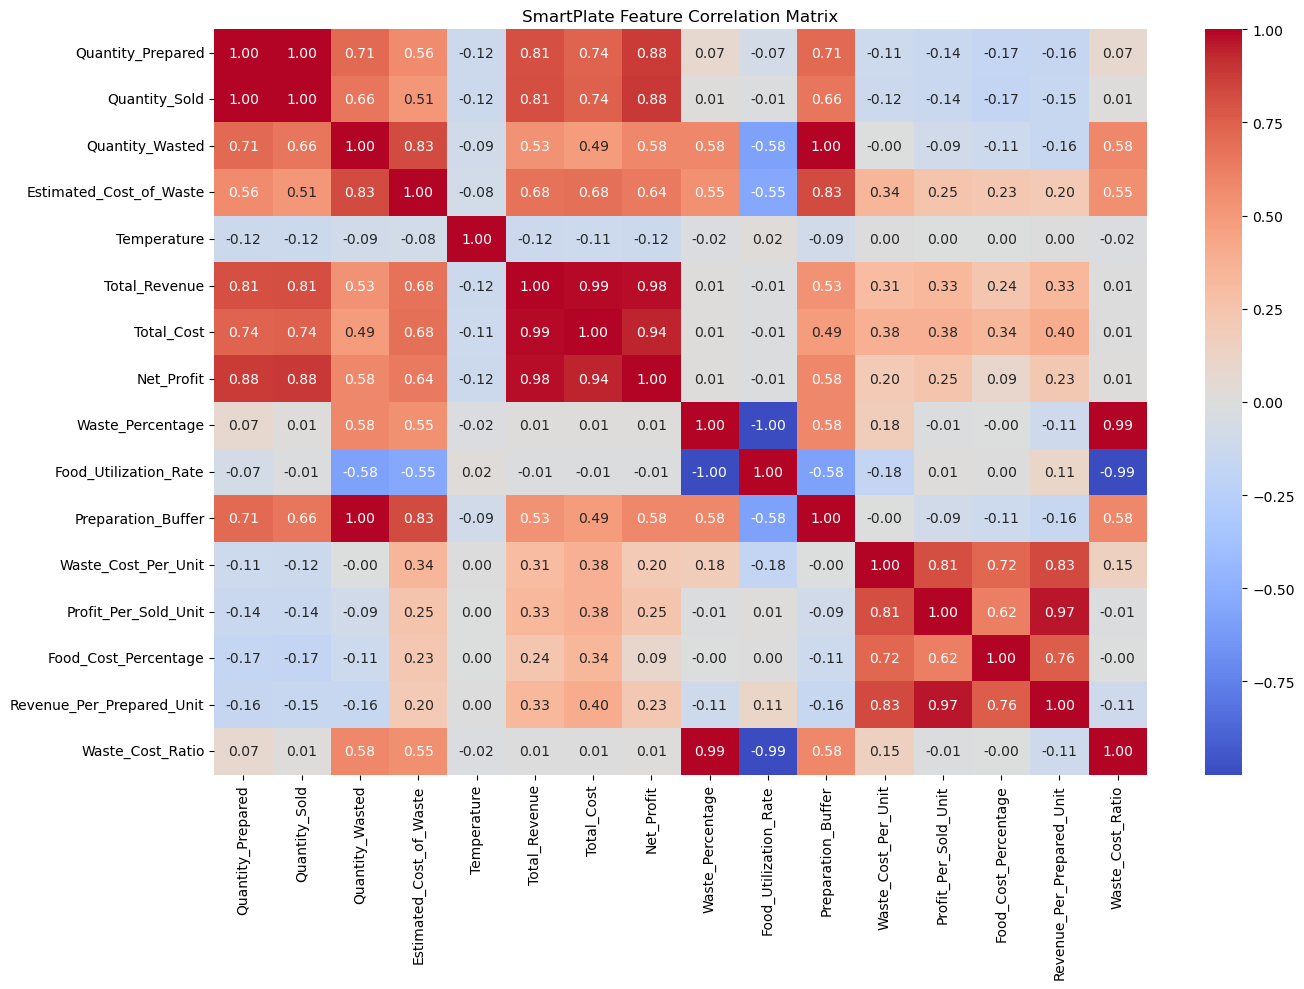

In [33]:
# ============================================================
# FEATURE CORRELATION
# ============================================================

correlation_features = [
    'Quantity_Prepared',
    'Quantity_Sold',
    'Quantity_Wasted',
    'Estimated_Cost_of_Waste',
    'Temperature',
    'Total_Revenue',
    'Total_Cost',
    'Net_Profit',
    'Waste_Percentage',
    'Food_Utilization_Rate',
    'Preparation_Buffer',
    'Waste_Cost_Per_Unit',
    'Profit_Per_Sold_Unit',
    'Food_Cost_Percentage',
    'Revenue_Per_Prepared_Unit',
    'Waste_Cost_Ratio'
]

available_corr_features = [
    col for col in correlation_features
    if col in df.columns
]

correlation_matrix = (
    df[available_corr_features]
    .corr()
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title(
    'SmartPlate Feature Correlation Matrix'
)

plt.tight_layout()

plt.show()

In [34]:
# ============================================================
# SAVE FEATURE ENGINEERED DATASET
# ============================================================

output_file = 'smartplate_features.csv'

df.to_csv(
    output_file,
    index=False
)

print("=" * 70)
print("✅ FEATURE ENGINEERING COMPLETED")
print("=" * 70)

print(
    f"File saved successfully: {output_file}"
)

print(
    f"Final dataset shape: {df.shape}"
)

✅ FEATURE ENGINEERING COMPLETED
File saved successfully: smartplate_features.csv
Final dataset shape: (21900, 45)


In [35]:
# ============================================================
# FINAL VERIFICATION
# ============================================================

print("=" * 70)
print("FINAL SMARTPLATE DATASET")
print("=" * 70)

print("\nRows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\n✅ Feature Engineering Phase Completed.")

FINAL SMARTPLATE DATASET

Rows: 21900
Columns: 45

Columns:
1. Date
2. Day_of_Week
3. Food_Item
4. Food_Category
5. Meal_Type
6. Quantity_Prepared
7. Quantity_Sold
8. Quantity_Wasted
9. Actual_Demand
10. Number_of_Students
11. Weather
12. Temperature
13. Special_Event_Flag
14. Holiday_Flag
15. Food_Cost_Per_Unit
16. Selling_Price_Per_Unit
17. Estimated_Cost_of_Waste
18. Unmet_Demand
19. Stockout_Flag
20. Waste_Percentage
21. Food_Utilization_Rate
22. Preparation_Buffer
23. Waste_Cost_Per_Unit
24. Total_Revenue
25. Total_Cost
26. Net_Profit
27. Profit_Per_Sold_Unit
28. Food_Cost_Percentage
29. High_Waste_Flag
30. Stockout_Status
31. Temperature_Category
32. Food_Popularity_Group
33. Waste_Severity
34. Revenue_Per_Prepared_Unit
35. Waste_Cost_Ratio
36. Category_Avg_Waste_Percentage
37. Meal_Avg_Waste_Percentage
38. Year
39. Month
40. Month_Name
41. Weekday_Number
42. Weekday_Name
43. Is_Weekend
44. Demand_Per_Student
45. Demand_Based_Preparation_Buffer

Missing Values:
0

Duplicate Rows: